In [1]:
#Import Libraries and load data 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

df = pd.read_csv(
    "data/processed datasets/diabetes_ml.csv"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (253680, 22)


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0,1,1,1,40,1,0,0,0,0,1,0,1,0,5,18,15,1,0,9,4,3
1,0,0,0,0,25,1,0,0,1,0,0,0,0,1,3,0,0,0,0,7,6,1
2,0,1,1,1,28,0,0,0,0,1,0,0,1,1,5,30,30,1,0,9,4,8
3,0,1,0,1,27,0,0,0,1,1,1,0,1,0,2,0,0,0,0,11,3,6
4,0,1,1,1,24,0,0,0,1,1,1,0,1,0,2,3,0,0,0,11,5,4


In [3]:
#Descriptive Statistics and Data Exploration

# Display dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

# Check diabetes class distribution
print("\nDiabetes Class Distribution:")
print(
    df["Diabetes_012"]
    .value_counts()
    .sort_index()
)

# Select numerical health indicators
numeric_features = [
    "BMI",
    "MentHlth",
    "PhysHlth"
]

# Calculate descriptive statistics
statistics = df[numeric_features].describe().T

print("\nDescriptive Statistics:")
display(statistics.round(2))


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   Diabetes_012          253680 non-null  int64
 1   HighBP                253680 non-null  int64
 2   HighChol              253680 non-null  int64
 3   CholCheck             253680 non-null  int64
 4   BMI                   253680 non-null  int64
 5   Smoker                253680 non-null  int64
 6   Stroke                253680 non-null  int64
 7   HeartDiseaseorAttack  253680 non-null  int64
 8   PhysActivity          253680 non-null  int64
 9   Fruits                253680 non-null  int64
 10  Veggies               253680 non-null  int64
 11  HvyAlcoholConsump     253680 non-null  int64
 12  AnyHealthcare         253680 non-null  int64
 13  NoDocbcCost           253680 non-null  int64
 14  GenHlth               253680 non-null  int64
 15  MentHlth              25

,count,mean,std,min,25%,50%,75%,max
BMI,253680.0,28.38,6.61,12.0,24.0,27.0,31.0,98.0
MentHlth,253680.0,3.18,7.41,0.0,0.0,0.0,2.0,30.0
PhysHlth,253680.0,4.24,8.72,0.0,0.0,0.0,3.0,30.0


Diabetes Class Distribution:


,Count,Percentage
Diabetes_012,,
0,213703,84.24
1,4631,1.83
2,35346,13.93


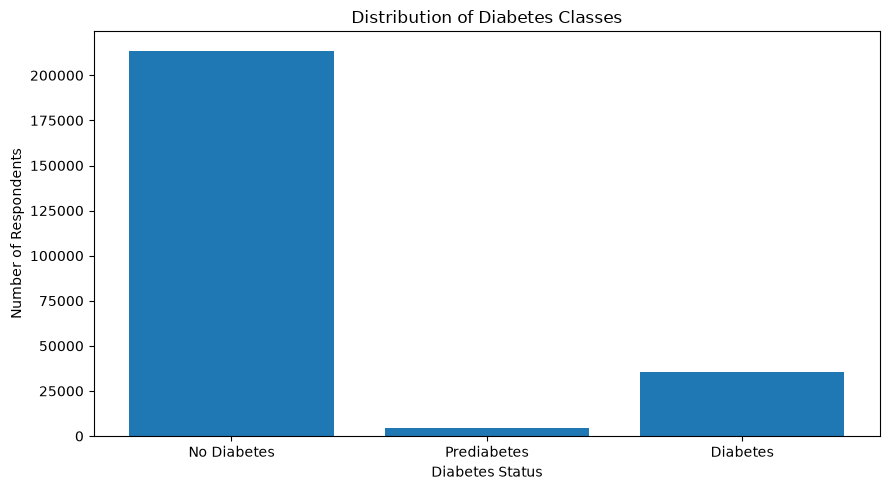

In [5]:
#Class Distribution Analysis

# Count records in each diabetes class
class_counts = (
    df["Diabetes_012"]
    .value_counts()
    .reindex([0, 1, 2], fill_value=0)
)

# Calculate class percentages
class_percentages = (
    class_counts / len(df) * 100
)

# Create summary table
class_summary = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages.round(2)
})

print("Diabetes Class Distribution:")
display(class_summary)

# Class labels
labels = [
    "No Diabetes",
    "Prediabetes",
    "Diabetes"
]

# Create bar chart
plt.figure(figsize=(9, 5))

plt.bar(labels, class_counts.values)

plt.title("Distribution of Diabetes Classes")
plt.xlabel("Diabetes Status")
plt.ylabel("Number of Respondents")

plt.tight_layout()
plt.show()


BMI Statistics by Diabetes Status:


,count,mean,median,std,min,max
Diabetes_012,,,,,,
0,213703,27.74,27.0,6.26,12,98
1,4631,30.72,30.0,6.96,13,96
2,35346,31.94,31.0,7.36,13,98


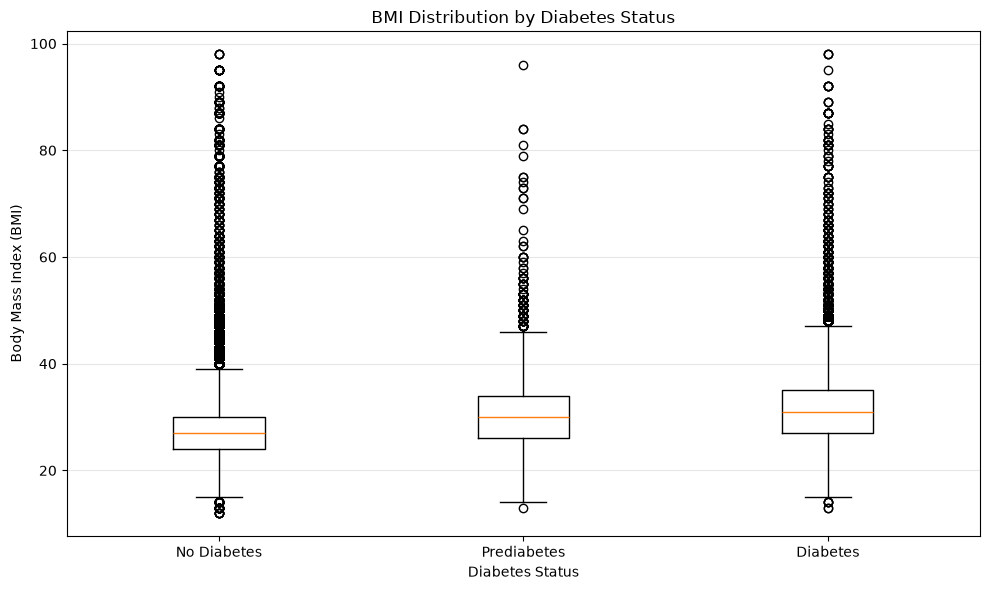

In [7]:

# ==========================================
# STEP 4: BMI ANALYSIS BY DIABETES STATUS
# ==========================================

# Calculate BMI statistics for each diabetes class
bmi_summary = df.groupby(
    "Diabetes_012"
)["BMI"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

# Display BMI summary
print("BMI Statistics by Diabetes Status:")
display(bmi_summary.round(2))

# Prepare BMI data for each diabetes class
bmi_groups = [
    df.loc[df["Diabetes_012"] == i, "BMI"].dropna()
    for i in [0, 1, 2]
]

# Create BMI boxplot
plt.figure(figsize=(10, 6))

plt.boxplot(
    bmi_groups,
    tick_labels=[
        "No Diabetes",
        "Prediabetes",
        "Diabetes"
    ]
)

plt.title("BMI Distribution by Diabetes Status")
plt.xlabel("Diabetes Status")
plt.ylabel("Body Mass Index (BMI)")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


Diabetes_012,0,1,2
Age,,,
1,98.26,0.37,1.37
2,97.45,0.71,1.84
3,96.53,0.65,2.82
4,94.44,1.03,4.53
5,92.49,1.01,6.50
6,89.64,1.57,8.79
7,86.68,1.59,11.74
8,84.39,1.78,13.83
9,80.64,2.11,17.25


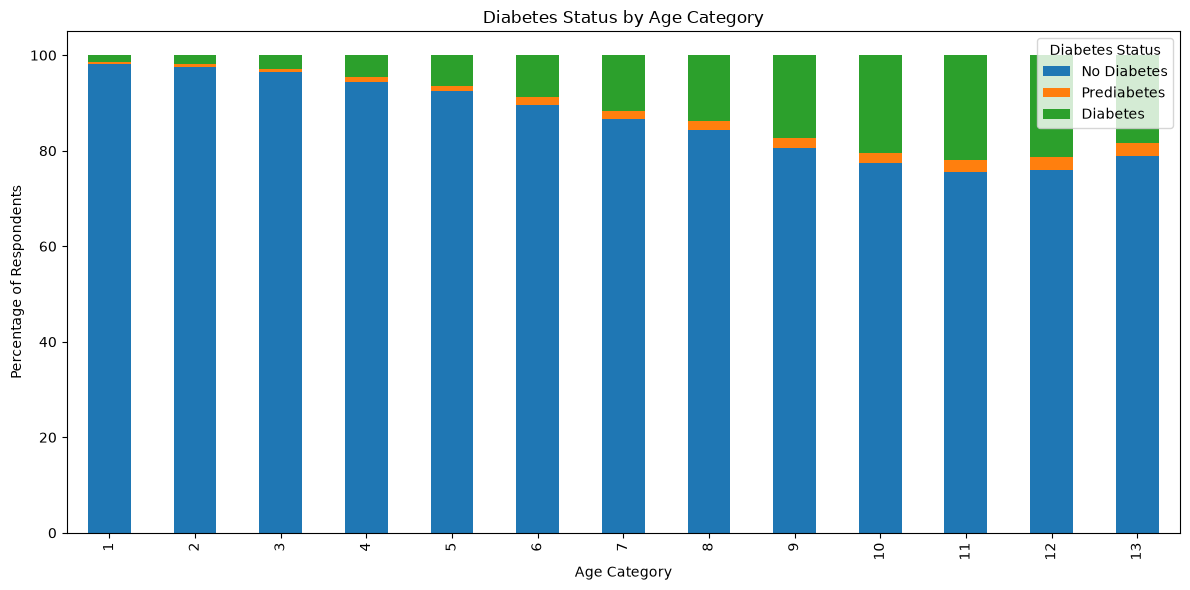

In [8]:
#Age Analysis

age_distribution = pd.crosstab(
    df["Age"],
    df["Diabetes_012"],
    normalize="index"
) * 100

age_distribution = age_distribution.reindex(
    columns=[0, 1, 2],
    fill_value=0
)

display(age_distribution.round(2))

age_distribution.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Diabetes Status by Age Category")
plt.xlabel("Age Category")
plt.ylabel("Percentage of Respondents")

plt.legend(
    ["No Diabetes", "Prediabetes", "Diabetes"],
    title="Diabetes Status"
)

plt.tight_layout()
plt.show()


In [9]:
#Binary Health Indicator Analysis

def analyse_binary_feature(column, title):

    # Calculate percentages for each diabetes class
    distribution = pd.crosstab(
        df[column],
        df["Diabetes_012"],
        normalize="index"
    ) * 100

    distribution = distribution.reindex(
        index=[0, 1],
        columns=[0, 1, 2],
        fill_value=0
    )

    # Display statistical results
    print(f"\n{title}")
    display(distribution.round(2))

    # Create stacked bar chart
    ax = distribution.plot(
        kind="bar",
        stacked=True,
        figsize=(9, 5)
    )

    ax.set_title(title)
    ax.set_xlabel(f"{column} (0 = No, 1 = Yes)")
    ax.set_ylabel("Percentage of Respondents")

    ax.legend(
        ["No Diabetes", "Prediabetes", "Diabetes"],
        title="Diabetes Status"
    )

    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    return distribution



Diabetes Status by High Blood Pressure


Diabetes_012,0,1,2
HighBP,,,
0,92.78,1.19,6.04
1,72.88,2.68,24.45


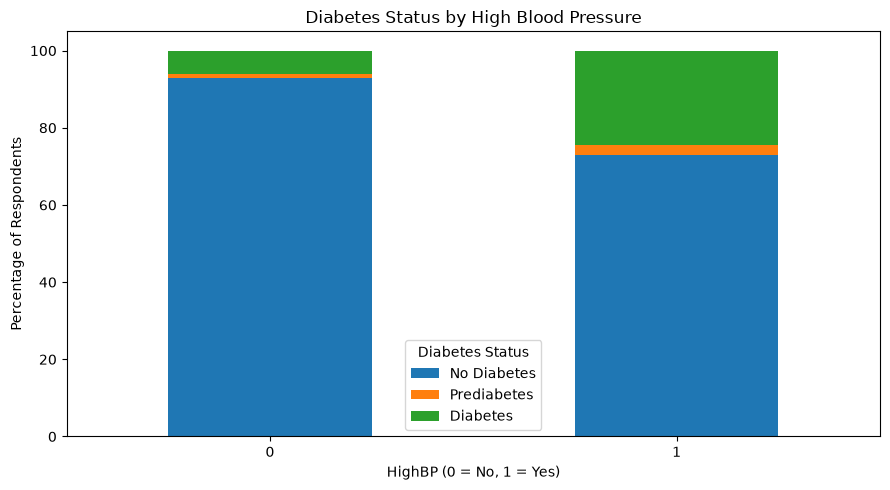


Diabetes Status by High Cholesterol


Diabetes_012,0,1,2
HighChol,,,
0,90.82,1.20,7.98
1,75.31,2.67,22.01


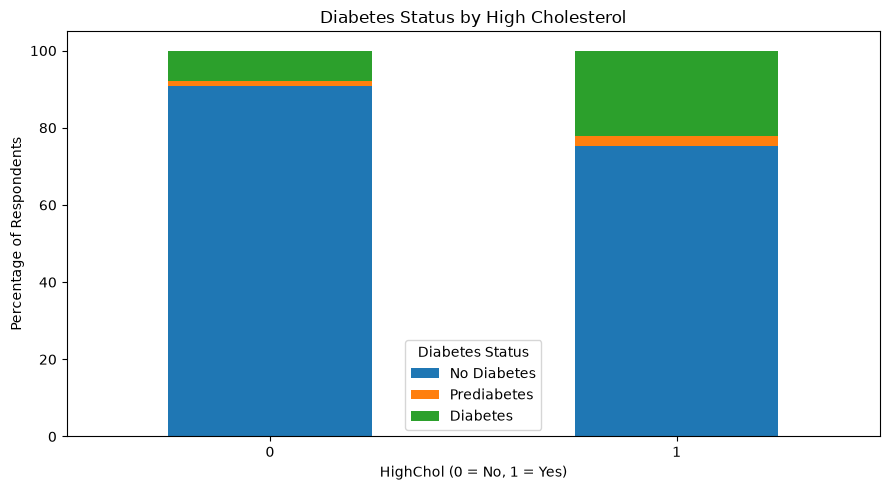


Diabetes Status by Physical Activity


Diabetes_012,0,1,2
PhysActivity,,,
0,76.44,2.41,21.14
1,86.75,1.64,11.61


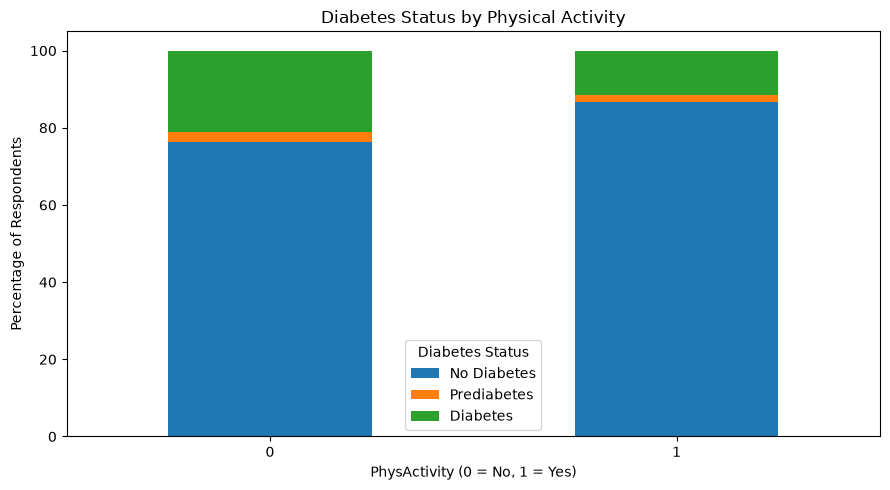


Diabetes Status by Smoking History


Diabetes_012,0,1,2
Smoker,,,
0,86.28,1.66,12.06
1,81.68,2.03,16.29


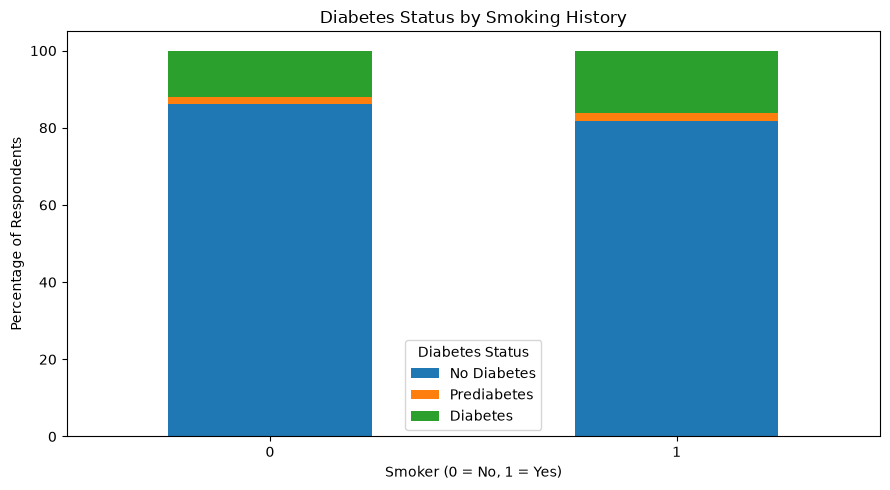

In [10]:
#High Blood Pressure Analysis

bp_results = analyse_binary_feature(
    "HighBP",
    "Diabetes Status by High Blood Pressure"
)

#High Cholesterol Analysis
chol_results = analyse_binary_feature(
    "HighChol",
    "Diabetes Status by High Cholesterol"
)

#Physical Activity Analysis
activity_results = analyse_binary_feature(
    "PhysActivity",
    "Diabetes Status by Physical Activity"
)

#Smoking Analysis
smoking_results = analyse_binary_feature(
    "Smoker",
    "Diabetes Status by Smoking History"
)
